# Solutions to the exercises of Chapter 4

Sample solutions for [Chapter 4, Two-dimensional steady conduction](../../notebooks/part1_conduction/04_two_dimensional.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import reference
from engtransport.plotting import panel_label, use_style

use_style()

## Exercise 1. A buried cable

The heat generated per metre, $I^2\rho_e/A$, crosses the PVC and then the soil, in series:
$I_{\max}^2\rho_e/A = (T_{\max} - T_s)/(R'_{\rm PVC} + R'_{\rm soil})$, with $R'_{\rm soil}$
from Eq. (4.7).

In [2]:
r_c, t_pvc, k_pvc = 2.26e-3, 1.2e-3, 0.19
rho_e, A_cu = 2.06e-8, 16e-6            # resistivity of copper at 70 C; cross-section
z_c, T_max, T_surface = 0.7, 70.0, 20.0
r_out = r_c + t_pvc
R_pvc = math.log(r_out / r_c) / (2 * math.pi * k_pvc)
for k_s in (1.0, 0.4):
    R_soil = math.acosh(z_c / r_out) / (2 * math.pi * k_s)
    q = (T_max - T_surface) / (R_pvc + R_soil)
    print(f"k_s = {k_s}: R'_PVC = {R_pvc:.3f}, R'_soil = {R_soil:.3f} m K/W; q' = {q:.1f} W/m,"
          f" ampacity {math.sqrt(q * A_cu / rho_e):.0f} A")

k_s = 1.0: R'_PVC = 0.357, R'_soil = 0.955 m K/W; q' = 38.1 W/m, ampacity 172 A
k_s = 0.4: R'_PVC = 0.357, R'_soil = 2.388 m K/W; q' = 18.2 W/m, ampacity 119 A


In moist soil the cable carries 172 A, more than twice the 79 A it carries in air at
30 °C. The soil, $k_s = 1$ W/(m K), conducts far better than air carries heat away from a
thin cable by convection and radiation, and it is cooler. If the soil around the cable
dries out, which the heat of the cable itself encourages, its resistance more than
doubles and the ampacity falls to 119 A. A cable sized for moist soil can then overheat.
This is why standards for buried cables specify the thermal resistivity of the soil, and
why cables are often laid in a bed of sand chosen to stay moist.

## Exercise 2. The ground surface

With a surface coefficient $h$, the ground surface is no longer isothermal. The rule says
that the extra resistance $1/h$ per unit area acts like a layer of soil $k_s/h$ thick, so
the pipe behaves as if it were at depth $z + k_s/h$. The finite differences solve the real
problem, with the convective surface condition (in the solver, $k = 1$ and
$H = h/k_s$):

In [3]:
k_s, h_surf, z = 1.5, 15.0, 1.0
for name, r in (("bare steel pipe", 0.05715), ("pre-insulated casing", 0.1125)):
    S_fixed = 2 * math.pi / math.acosh(z / r)
    S_rule = 2 * math.pi / math.acosh((z + k_s / h_surf) / r)
    q = []
    for far in (("temperature", 0.0), ("insulated",)):          # the two bounds of Chapter 4
        out = reference.laplace_2d_fd(8.0, 8.0, 0.02, circles=[(0.0, z, r, 1.0)],
                                      top=("convection", h_surf / k_s, 0.0), left=("insulated",),
                                      right=far, bottom=far)
        q.append(2 * out["Q_circles"][0])
    S_fd = np.mean(q)
    print(f"{name}: S' fixed surface {S_fixed:.4f}, with h by finite differences {S_fd:.4f},"
          f" effective depth {S_rule:.4f} ({S_rule / S_fd - 1:+.2%})")

R_ins = math.log(0.1125 / 0.05715) / (2 * math.pi * 0.027)
for name, S in (("fixed surface", 2 * math.pi / math.acosh(z / 0.1125)), ("with h", 2 * math.pi / math.acosh((z + 0.1) / 0.1125))):
    print(f"pre-insulated supply pipe, {name}: {110 / (R_ins + 1 / (S * k_s)):.2f} W/m")

bare steel pipe: S' fixed surface 1.7677, with h by finite differences 1.7209, effective depth 1.7215 (+0.03%)


pre-insulated casing: S' fixed surface 2.1856, with h by finite differences 2.1150, effective depth 2.1151 (+0.00%)
pre-insulated supply pipe, fixed surface: 25.60 W/m
pre-insulated supply pipe, with h: 25.54 W/m


The effective-depth rule agrees with the finite differences to 0.03 % for the bare pipe
and better for the casing. Here $k_s/h = 0.1$ m, a tenth of the depth, and the surface
resistance lowers the bare pipe's loss by 2.6 %; for the pre-insulated pipe the change is
only 0.2 %, because the soil itself is a small part of the resistance.

## Exercise 3. Wet insulation

In [4]:
r1, r2, z, k_s = 0.05715, 0.1125, 1.0, 1.5
R_soil = math.acosh(z / r2) / (2 * math.pi * k_s)
for name, k_ins in (("dry foam", 0.027), ("wet foam", 0.15)):
    R_ins = math.log(r2 / r1) / (2 * math.pi * k_ins)
    q = 110.0 / (R_ins + R_soil)
    print(f"{name}: q' = {q:5.1f} W/m, soil {R_soil / (R_ins + R_soil):.0%} of the resistance,"
          f" {q * 1000 * 8760 / 1e6:.0f} MWh per km per year")
q_bare = 2 * math.pi * k_s * 110.0 / math.acosh(z / r1)
print(f"no insulation: {q_bare:.0f} W/m, {q_bare * 1000 * 8760 / 1e6:.0f} MWh per km per year")

dry foam: q' =  25.6 W/m, soil 7% of the resistance, 224 MWh per km per year
wet foam: q' = 107.5 W/m, soil 30% of the resistance, 941 MWh per km per year
no insulation: 292 W/m, 2555 MWh per km per year


Soaked foam raises the loss of the supply pipe from 25.6 to 107 W/m, four times as much,
an extra 720 MWh per kilometre in a year at a steady 110 °C. The soil now carries 30 % of
the resistance, so its moisture starts to matter. A pipe with no insulation at all loses
292 W/m, 2560 MWh per kilometre per year. Wet insulation is also the start of corrosion of
the steel pipe, which is why pre-insulated pipes carry alarm wires in the foam that detect
moisture.

## Exercise 4. Two hot faces

The problem with the bottom and left faces hot is the sum of two problems, each with one
hot face. The second is the first rotated: $\theta_{\rm left}(x, y) = \theta_{\rm
bottom}(y, x)$. At the centre each contributes 1/4, so $\theta = 1/2$ and the centre is at
60 °C.

(x, y) = (0.5, 0.5) W: superposition 60.000 C, finite differences 60.000 C
(x, y) = (0.25, 0.25) W: superposition 89.125 C, finite differences 89.124 C
(x, y) = (0.75, 0.25) W: superposition 60.000 C, finite differences 60.000 C


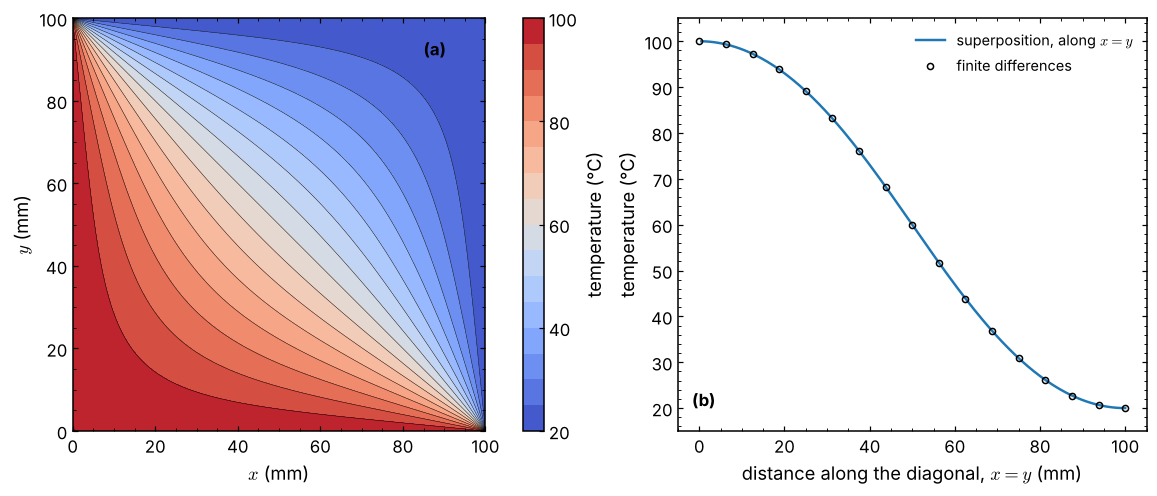

In [5]:
def bar_theta(x, y, n_terms=401):
    """Eq. (4.3) for a square bar of unit side: hot face y = 0, the other three cold."""
    x, y = np.broadcast_arrays(np.asarray(x, float), np.asarray(y, float))
    n = np.arange(1, n_terms + 1, 2).reshape((-1,) + (1,) * x.ndim)
    ratio = np.exp(-n * np.pi * y) * (1 - np.exp(-2 * n * np.pi * (1 - y))) / (1 - np.exp(-2 * n * np.pi))
    return np.sum(4 / (n * np.pi) * np.sin(n * np.pi * x) * ratio, axis=0)


two_faces = lambda x, y: bar_theta(x, y) + bar_theta(y, x)
T0, T1 = 20.0, 100.0
n = 161
fd = reference.laplace_2d_fd(1.0, 1.0, 1.0 / (n - 1), top=("temperature", 1.0), left=("temperature", 1.0),
                             bottom=("temperature", 0.0), right=("temperature", 0.0))
for (xp, yp) in ((0.5, 0.5), (0.25, 0.25), (0.75, 0.25)):
    i, j = int(round(xp * (n - 1))), int(round(yp * (n - 1)))
    print(f"(x, y) = ({xp}, {yp}) W: superposition {T0 + (T1 - T0) * float(two_faces(xp, yp)):.3f} C,"
          f" finite differences {T0 + (T1 - T0) * fd['T'][j, i]:.3f} C")

xs = np.linspace(0, 1, 201)
X, Y = np.meshgrid(xs, xs)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.4))
cs = ax1.contourf(X * 100, Y * 100, T0 + (T1 - T0) * two_faces(X, Y), levels=np.arange(20, 101, 5), cmap="coolwarm")
ax1.contour(X * 100, Y * 100, T0 + (T1 - T0) * two_faces(X, Y), levels=np.arange(25, 100, 5), colors="k", linewidths=0.3)
fig.colorbar(cs, ax=ax1, label="temperature (°C)", ticks=[20, 40, 60, 80, 100])
ax1.set_xlabel("$x$ (mm)")
ax1.set_ylabel("$y$ (mm)")
ax1.set_aspect("equal")
panel_label(ax1, "(a)", x=0.85)

ax2.plot(xs[1:] * 100, T0 + (T1 - T0) * two_faces(xs[1:], xs[1:]), "C0", label="superposition, along $x = y$")
ax2.plot(fd["x"][::10] * 100, T0 + (T1 - T0) * np.diag(fd["T"])[::10], "ko", ms=4, mfc="none",
         label="finite differences")
ax2.set_xlabel("distance along the diagonal, $x = y$ (mm)")
ax2.set_ylabel("temperature (°C)")
ax2.set_ylim(15, 105)
ax2.legend(loc="upper right")
panel_label(ax2, "(b)", y=0.1)
plt.show()

**Figure S4.1.** (a) Temperature in the square bar with its bottom and left faces at
100 °C and the other two at 20 °C, by superposition of two series (4.3). (b) The
temperature along the diagonal from the hot corner to the cold one, from superposition and
from finite differences.

Superposition and finite differences agree to a few thousandths of a kelvin. Along the
diagonal the temperature falls from 100 °C at the hot corner, through 60 °C at the centre,
to 20 °C at the cold corner; by the symmetry of the problem, the temperatures at
$(x, y)$ and $(1 - x, 1 - y)$ add up to 120 °C.